<a href="https://colab.research.google.com/github/julia-zhmurko/JuliaZhmurko-ML/blob/main/%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D1%96_%D1%80%D0%BE%D0%B1%D0%BE%D1%82%D0%B8/%D0%96%D0%BC%D1%83%D1%80%D0%BA%D0%BE_%D0%AE%D0%BB%D1%96%D1%8F_%D0%A4%D0%86%D0%A2_4_10_%D0%9B%D0%A0_7_%D0%9B%D0%BE%D0%B3_%D1%80%D0%B5%D0%B3%D1%80%D0%B5%D1%81%D1%96%D1%8F_%D0%B2%D1%80%D1%8F%D1%82%D1%83%D0%B2%D0%B0%D1%82%D0%B8_%D0%BF%D1%80%D0%B8%D0%BD%D1%86%D0%B5%D1%81%D1%83_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

**Виконала:** студентка групи ФІТ 4-10 Жмурко Юлія Андріївна

**Була присутня на парі (04.11.2026)**

### 1. Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

###**Пояснення:**

Імпортуємо необхідні бібліотеки для роботи з даними, їх візуалізації, побудови, налаштування та оцінювання моделей машинного навчання.

* **pandas**, **numpy** – для обробки та аналізу даних;

* **matplotlib**, **seaborn** – для побудови графіків і візуалізації результатів;

* **train_test_split** – для поділу даних на навчальну та тестову вибірки;

* **GridSearchCV**, **RandomizedSearchCV** – для підбору оптимальних гіперпараметрів моделей;

* **StandardScaler** – для стандартизації числових ознак;

* **LogisticRegression**, **SVC**, **DecisionTreeClassifier** – для побудови та порівняння моделей логістичної регресії, методу опорних векторів і дерева рішень;

* **accuracy_score**, **confusion_matrix**, **classification_report**, **f1_score** – для оцінювання якості класифікації.

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [2]:
# Варіант 1. Завантаження файлу в Google Colab
from google.colab import files
files.upload()
df = pd.read_csv('data.csv')
df.head()

Saving data.csv to data.csv


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


###**Пояснення:**

Завантажуємо датасет `Cure the Princess`, який використовуватиметься для побудови та оцінювання моделей бінарної класифікації.

Передбачено два способи завантаження даних:

* Варіант 1 – завантаження файлу `data.csv` з комп’ютера до Google Colab за допомогою `files.upload()`.

* Варіант 2 – автоматичне завантаження датасету з Kaggle за допомогою бібліотеки `kagglehub`.

Функція `pd.read_csv()` зчитує дані у DataFrame `df`, а метод `df.head()` відображає перші 5 рядків для ознайомлення зі структурою датасету.

Датасет містить 13 числових ознак, які характеризують кількість магічних інгредієнтів, та цільову змінну `Cured`, що визначає результат лікування принцеси (0 – не вилікувана, 1 – вилікувана).

In [3]:
# Варіант 2. Завантаження датасету через KaggleHub
import kagglehub
import os
path = kagglehub.dataset_download('unmoved/cure-the-princess')
df = pd.read_csv(os.path.join(path, 'data.csv'))
df

100%|██████████| 49.2k/49.2k [00:00<00:00, 35.3MB/s]

Extracting files...


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2333,9.4,2.2,15.8,5.9,29.7,18.7,11.5,13.1,15.3,22.5,10.1,4.7,13.8,0
2334,12.1,7.6,20.6,5.3,18.9,19.1,9.4,11.9,21.8,12.0,26.7,8.4,24.4,1
2335,15.2,33.2,7.2,14.5,16.0,16.7,1.2,32.5,34.5,25.9,3.9,18.0,19.2,1
2336,2.0,17.0,33.2,13.2,29.1,35.5,19.7,30.3,30.7,4.3,15.7,20.5,2.1,1


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [4]:
# TODO: виведіть перші рядки, структуру й розмір датасету
# Підказка: head(), info(), shape

display(df.head())

df.info()

print("\nРозмір датасету:", df.shape)
print("Кількість рядків:", df.shape[0])
print("Кількість стовпців:", df.shape[1])

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB

Розмір датасету: (2338, 14)
Кількість рядків: 2338
Кількість стовпців: 14


###**Пояснення:**

За допомогою `head()` переглядаємо перші 5 рядків датасету, `info()` отримуємо інформацію про назви стовпців, типи даних і кількість непорожніх значень, а `shape` визначаємо загальну кількість рядків і стовпців.

In [5]:
# TODO: перевірте кількість пропусків і дублікатів
# Підказка: isnull().sum(), duplicated().sum()

print("Пропущені значення:")
display(df.isnull().sum())

print("\nЗагальна кількість пропусків:", df.isnull().sum().sum())

print("Кількість дублікатів:", df.duplicated().sum())

Пропущені значення:


,0
Phoenix Feather,0
Unicorn Horn,0
Dragon's Blood,0
Mermaid Tears,0
Fairy Dust,0
Goblin Toes,0
Witch's Brew,0
Griffin Claw,0
Troll Hair,0
Kraken Ink,0



Загальна кількість пропусків: 0
Кількість дублікатів: 0


###**Пояснення:**

Перевіряємо наявність пропущених значень за допомогою `isnull().sum()` та визначаємо кількість повністю повторюваних рядків методом `duplicated().sum()`. Це дозволяє оцінити якість даних і необхідність їх очищення перед навчанням моделей.

In [6]:
# TODO: виведіть описову статистику
# Підказка: describe()

display(df.describe())

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


###**Пояснення:**

За допомогою методу `describe()` отримуємо основні статистичні характеристики числових ознак: кількість значень (`count`), середнє (`mean`), стандартне відхилення (`std`), мінімальне (`min`), максимальне (`max`) значення та квартилі (`25%`, `50%`, `75%`). Це дозволяє оцінити розподіл значень і виявити можливі особливості даних.

###**Висновок за первинним оглядом:**  
_Напишіть тут, чи є пропуски, дублікати та які особливості даних помітили._


За результатами первинного огляду встановлено, що датасет `Cure the Princess` містить 2338 записів і 14 стовпців, з яких 13 є числовими ознаками типу `float64`, а один – цільовою змінною `Cured` типу `int64`.

Перевірка якості даних показала, що пропущені значення та дублікати відсутні, тому додаткове очищення даних за цими критеріями не потрібне.

Аналіз описової статистики показав, що числові ознаки мають різні діапазони значень (від 1 до 44 залежно від ознаки), середні значення та стандартні відхилення. Це свідчить про доцільність стандартизації ознак перед навчанням моделей, чутливих до масштабу даних.

Цільова змінна `Cured` приймає значення 0 або 1, а її середнє значення становить приблизно 0,497, що вказує на майже збалансований розподіл класів.

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [7]:
# TODO: сформуйте X (ознаки) та y (Cured)
# TODO: створіть X_train, X_test, y_train, y_test
# Підказка: train_test_split(..., test_size=0.2, random_state=42)

X = df.drop(columns=['Cured'])
y = df['Cured']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42)

print("Розмір навчальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)

print("\nКількість цільових значень у навчальній вибірці:", y_train.shape[0])
print("Кількість цільових значень у тестовій вибірці:", y_test.shape[0])

Розмір навчальної вибірки: (1870, 13)
Розмір тестової вибірки: (468, 13)

Кількість цільових значень у навчальній вибірці: 1870
Кількість цільових значень у тестовій вибірці: 468


###**Пояснення:**

Відокремлюємо цільову змінну `Cured` від решти ознак за допомогою методу `drop()`. Матриця `X` містить 13 числових ознак, а змінна `y` – результати лікування принцеси (0 або 1).

За допомогою функції `train_test_split()` розділяємо датасет на навчальну (80%) та тестову (20%) вибірки. Параметр `random_state=42` забезпечує відтворюваність результатів.

У результаті отримано 1870 записів для навчання та 468 записів для тестування, кожен із яких містить 13 ознак. Навчальна вибірка використовуватиметься для аналізу даних, підготовки та навчання моделей, а тестова – для незалежного оцінювання їхньої якості.

### 5. Баланс класів на навчальній вибірці

In [8]:
# TODO: підрахуйте кількість спостережень кожного класу в y_train

print("Кількість спостережень кожного класу:")
display(y_train.value_counts())

print("\nВідсотковий розподіл класів:")
display(y_train.value_counts(normalize = True) * 100)

Кількість спостережень кожного класу:


,count
Cured,
0,946
1,924



Відсотковий розподіл класів:


,proportion
Cured,
0,50.588235
1,49.411765


###**Пояснення:**

За допомогою методу `value_counts()` визначаємо кількість спостережень кожного класу цільової змінної `Cured` у навчальній вибірці, а параметр `normalize=True` дозволяє обчислити їх відсоткове співвідношення.

У результаті отримано **946 спостережень (50,59%) для класу 0** та **924 спостереження (49,41%) для класу 1**. Отримані значення свідчать про майже рівномірний розподіл класів у навчальній вибірці.

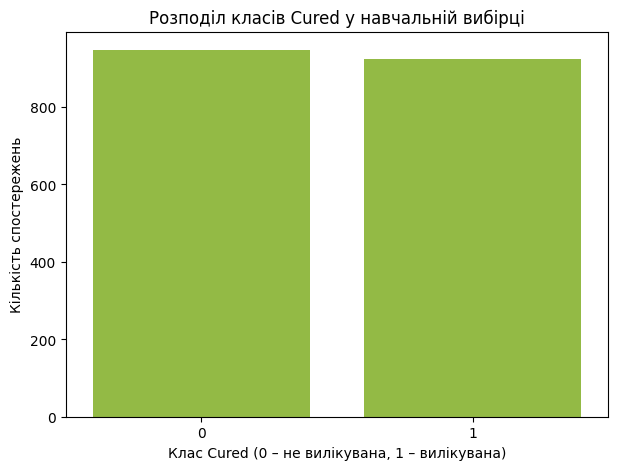

In [9]:
# TODO: побудуйте countplot для y_train
# Підказка: sns.countplot(x=y_train)

plt.figure(figsize = (7, 5))
sns.countplot(x = y_train, color = 'yellowgreen')
plt.title("Розподіл класів Cured у навчальній вибірці")
plt.xlabel("Клас Cured (0 – не вилікувана, 1 – вилікувана)")
plt.ylabel("Кількість спостережень")
plt.show()

###**Пояснення:**

За допомогою функції `sns.countplot()` будуємо стовпчикову діаграму розподілу класів цільової змінної `Cured` у навчальній вибірці. Висота кожного стовпчика відповідає кількості спостережень певного класу.

На побудованому графіку видно, що кількість спостережень класів 0 та 1 майже однакова, а різниця між ними становить лише 22 записи. Це підтверджує відсутність суттєвого дисбалансу класів.

###**Висновок:**  
_Чи збалансовані класи? Чому це може вплинути на оцінку моделі?_

За результатами аналізу встановлено, що **класи цільової змінної `Cured` у навчальній вибірці практично збалансовані**: клас 0 становить 50,59%, а клас 1 – 49,41% усіх спостережень.

Незначна різниця між кількістю спостережень класів не повинна суттєво впливати на навчання та оцінювання моделей. Збалансованість класів зменшує ризик зміщення моделей у бік одного з класів і дозволяє об'єктивніше оцінювати результати класифікації.

Отже, **застосування додаткових методів балансування класів не є необхідним**, а навчальну вибірку можна використовувати для подальшого навчання моделей логістичної регресії, SVM та дерева рішень.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

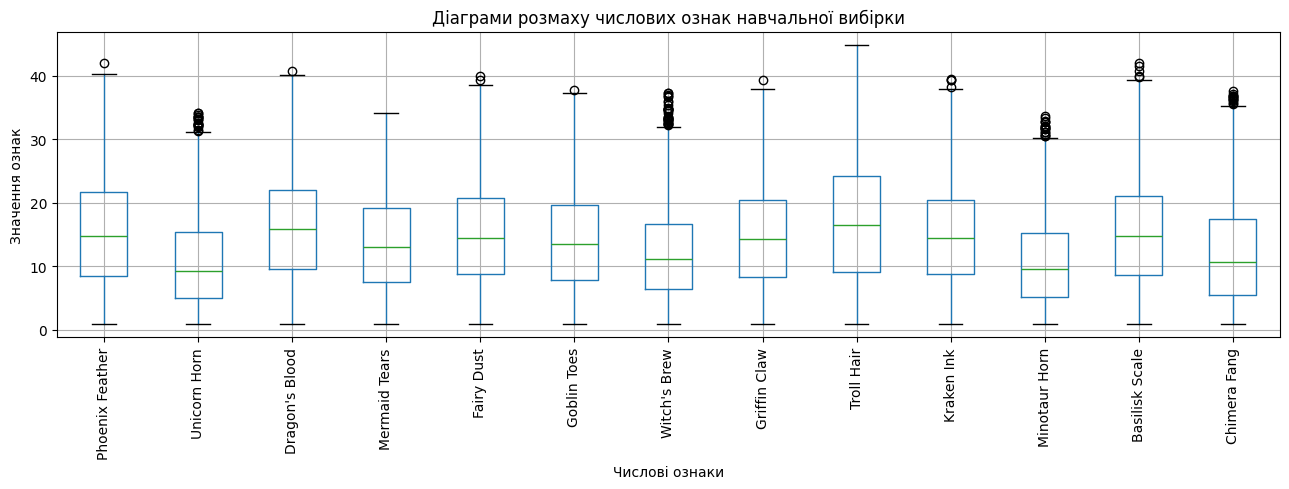

In [10]:
# TODO: побудуйте boxplot для X_train
# Підказка: X_train.boxplot(figsize=(13, 5), rot=90)

plt.figure(figsize = (13, 5))

X_train.boxplot(rot = 90)

plt.title("Діаграми розмаху числових ознак навчальної вибірки")
plt.xlabel("Числові ознаки")
plt.ylabel("Значення ознак")
plt.tight_layout()
plt.show()

###**Пояснення:**

За допомогою методу `boxplot()` будуємо діаграми розмаху для 13 числових ознак навчальної вибірки `X_train`. Діаграми дозволяють оцінити розподіл значень, медіану, міжквартильний розмах та наявність потенційних викидів.

На отриманому графіку видно, що більшість ознак мають окремі значення, які виходять за межі «вусів» діаграм. Найбільше таких значень візуально спостерігається для ознак `Witch's Brew`, `Unicorn Horn`, `Minotaur Horn` та `Chimera Fang`. Водночас для ознак `Mermaid Tears` і `Troll Hair` потенційних викидів не виявлено.

In [11]:
# TODO: обчисліть q1, q3, iqr для X_train
# TODO: знайдіть кількість викидів за межами [q1 - 1.5*iqr, q3 + 1.5*iqr]
# TODO: відсортуйте результат за спаданням

q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = (X_train < lower_bound) | (X_train > upper_bound)

outliers_count = outliers.sum()

outliers_count = outliers_count.sort_values(ascending = False)

print("Кількість потенційних викидів у кожній ознаці:")
display(outliers_count)

Кількість потенційних викидів у кожній ознаці:


,0
Witch's Brew,33
Unicorn Horn,20
Minotaur Horn,18
Chimera Fang,13
Basilisk Scale,5
Kraken Ink,4
Fairy Dust,2
Phoenix Feather,1
Dragon's Blood,1
Griffin Claw,1


###**Пояснення:**

За допомогою методу `quantile()` обчислюємо перший (`q1`) і третій (`q3`) квартилі для кожної ознаки навчальної вибірки `X_train`. На їх основі визначаємо міжквартильний розмах `iqr` та межі потенційних викидів за правилом 1,5 IQR.

Далі за допомогою логічних операцій порівняння та методу `sum()` підраховуємо кількість значень, що виходять за встановлені межі. Отримані результати сортуємо за спаданням методом `sort_values()`.

Найбільшу кількість потенційних викидів виявлено в ознаках **`Witch's Brew` – 33, `Unicorn Horn` – 20, `Minotaur Horn` – 18 та `Chimera Fang` – 13**. Для ознак `Mermaid Tears` і `Troll Hair` викиди відсутні.

###**Висновок про викиди:**  
_У яких ознаках їх найбільше? Чому не варто без перевірки видаляти всі такі рядки?_

За результатами дослідження встановлено, що **більшість числових ознак навчальної вибірки містять потенційні викиди**, визначені за правилом 1,5 IQR. Найбільшу їх кількість виявлено в ознаці `Witch's Brew` (33 значення), а також `Unicorn Horn` (20), `Minotaur Horn` (18) та `Chimera Fang` (13). Водночас ознаки `Mermaid Tears` і `Troll Hair` не містять потенційних викидів.

Виявлені значення не обов'язково є помилковими, оскільки можуть відображати реальні особливості даних. Їх автоматичне видалення може призвести до втрати корисної інформації та негативно вплинути на якість класифікації.


### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

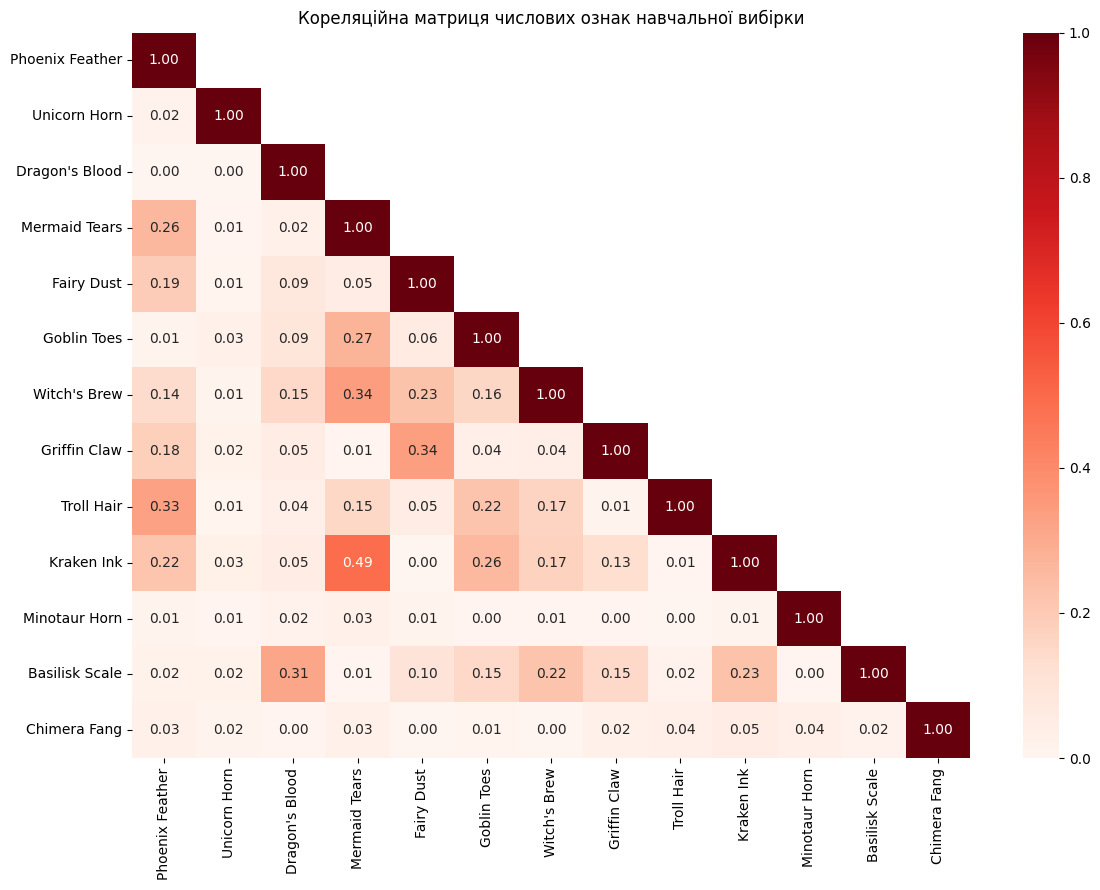

In [12]:
# TODO: обчисліть mtx = X_train.corr().abs()
# TODO: створіть маску верхнього трикутника за допомогою np.triu(...)
# TODO: побудуйте sns.heatmap(mtx, mask=..., annot=True, ...)
# Підказка: cmap='Reds', vmin=0, vmax=1

mtx = X_train.corr().abs()

mask = np.triu(np.ones_like(mtx, dtype = bool), k = 1)

plt.figure(figsize = (12, 9))

sns.heatmap(
    mtx,
    mask = mask,
    annot = True,
    fmt = ".2f",
    cmap = "Reds",
    vmin = 0,
    vmax = 1
)

plt.title("Кореляційна матриця числових ознак навчальної вибірки")
plt.tight_layout()
plt.show()

###**Пояснення:**

За допомогою методу `corr()` обчислюємо кореляційну матрицю числових ознак навчальної вибірки `X_train`, а метод `abs()` дозволяє отримати абсолютні значення коефіцієнтів кореляції.

Для уникнення дублювання значень створюємо маску верхнього трикутника матриці за допомогою `np.triu()` з параметром `k=1`, залишаючи головну діагональ видимою. Далі функцією `sns.heatmap()` будуємо теплову карту, де інтенсивність кольору відображає силу кореляційного зв'язку між ознаками.

На отриманій тепловій карті видно, що **більшість ознак мають слабкі кореляційні зв'язки**. Найвищу кореляцію спостерігаємо між `Mermaid Tears` і `Kraken Ink` (0,49). Також помітні зв'язки між `Mermaid Tears` і `Witch's Brew` (0,34), `Fairy Dust` і `Griffin Claw` (0,34), `Phoenix Feather` і `Troll Hair` (0,33) та `Dragon's Blood` і `Basilisk Scale` (0,31).

Отримані результати свідчать про відсутність сильних лінійних кореляцій між ознаками навчальної вибірки.

In [13]:
# TODO: дослідіть кореляцію кожної ознаки із Cured
# Підказка: pd.concat([X_train, y_train], axis=1).corr()

train_data = pd.concat([X_train, y_train], axis = 1)

correlation_target = train_data.corr()['Cured'].drop('Cured')

correlation_target = correlation_target.reindex(
    correlation_target.abs().sort_values(ascending = True).index
)

print("Кореляція числових ознак із цільовою змінною Cured:")
display(correlation_target.abs())

Кореляція числових ознак із цільовою змінною Cured:


,Cured
Mermaid Tears,0.002419
Unicorn Horn,0.004218
Griffin Claw,0.005871
Dragon's Blood,0.010119
Fairy Dust,0.014223
Phoenix Feather,0.020527
Minotaur Horn,0.021922
Kraken Ink,0.026598
Basilisk Scale,0.042277
Chimera Fang,0.047292


###**Пояснення:**

За допомогою функції `pd.concat()` об'єднуємо навчальну вибірку `X_train` із цільовою змінною `y_train`. Далі методом `corr()` обчислюємо коефіцієнти кореляції кожної числової ознаки із `Cured`, виключаючи кореляцію цільової змінної із самою собою за допомогою `drop()`.

Отримані коефіцієнти сортуємо за абсолютною величиною та виводимо за допомогою методу `abs()`, що дозволяє порівняти силу лінійного зв'язку ознак із результатом лікування принцеси.

Найсильніший зв'язок із цільовою змінною мають ознаки **`Troll Hair` (0,4888)** та **`Witch's Brew` (0,2470)**. Значно слабші кореляції спостерігаються для `Goblin Toes` (0,0526), `Chimera Fang` (0,0473) та `Basilisk Scale` (0,0423). Найменшу кореляцію має ознака `Mermaid Tears` (0,0024).

Отримані результати свідчать, що найбільш виражений лінійний зв'язок із цільовою змінною мають `Troll Hair` та `Witch's Brew`, тоді як для більшості інших ознак він є дуже слабким.

###**Висновок про кореляції:**  
_Назвіть пари найбільш корельованих ознак та ознаки з найсильнішим зв’язком із Cured._

За результатами кореляційного аналізу навчальної вибірки встановлено, що **більшість числових ознак мають слабкі лінійні взаємозв'язки між собою**. Найвищий коефіцієнт кореляції за модулем виявлено між ознаками `Mermaid Tears` і `Kraken Ink` (0,49). Оскільки сильних кореляційних зв'язків між ознаками не спостерігається, суттєвих ознак мультиколінеарності на цьому етапі не виявлено.

Аналіз кореляції з цільовою змінною `Cured` показав, що **найсильніший лінійний зв'язок мають ознаки `Troll Hair` (0,4888) та `Witch's Brew` (0,2470)**, тоді як для решти ознак коефіцієнти кореляції за модулем не перевищують 0,053.

Отже, отримані результати дозволяють визначити ознаки з найбільш вираженим лінійним зв'язком із результатом лікування принцеси. Водночас слабка кореляція не обов'язково свідчить про відсутність впливу ознаки на цільову змінну, оскільки залежності можуть бути нелінійними.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [14]:
# TODO: створіть scaler = StandardScaler()
# TODO: отримайте X_train_scaled і X_test_scaled

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Розмір стандартизованої навчальної вибірки:", X_train_scaled.shape)
print("Розмір стандартизованої тестової вибірки:", X_test_scaled.shape)

print("\nПерші 5 рядків стандартизованої навчальної вибірки:")
display(pd.DataFrame(X_train_scaled, columns = X_train.columns).head())

Розмір стандартизованої навчальної вибірки: (1870, 13)
Розмір стандартизованої тестової вибірки: (468, 13)

Перші 5 рядків стандартизованої навчальної вибірки:


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang
0,-0.432505,0.730574,0.090274,-0.517792,-0.298541,0.295646,-1.403805,-0.590516,-0.233777,-0.151879,0.522194,-0.923248,0.722121
1,2.239856,-0.927903,-0.878533,0.268632,0.075006,1.093785,-0.128719,-0.677185,1.819072,-0.863727,-0.173564,0.209048,-0.947331
2,1.287899,-0.681187,0.150076,-0.570220,-0.901036,0.282977,-0.336896,-1.259107,0.401877,-1.313315,0.820376,1.364452,0.108352
3,-0.833933,-1.202031,-0.136977,2.077406,1.075148,-1.642693,2.720706,0.115219,-0.254618,0.684854,-0.130966,0.336142,0.439787
4,-1.453279,0.182317,-0.256583,0.753593,2.002990,2.031283,0.430757,2.096229,2.340099,-0.788796,1.019164,2.196343,-0.161707


###**Пояснення:**

Виконуємо стандартизацію числових ознак за допомогою `StandardScaler`, який перетворює значення ознак так, щоб їхнє середнє значення дорівнювало приблизно 0, а стандартне відхилення – 1.

Для навчальної вибірки `X_train` використовуємо метод `fit_transform()`, який обчислює параметри стандартизації та застосовує перетворення. Для тестової вибірки `X_test` використовуємо лише метод `transform()`, застосовуючи параметри, отримані на навчальних даних. Це дозволяє уникнути витоку інформації з тестової вибірки.

У результаті отримано стандартизовані вибірки розмірами (1870, 13) для навчання та (468, 13) для тестування. Перегляд перших п'яти рядків показав, що числові значення ознак перетворено до нового масштабу, при цьому кількість записів та ознак залишилася незмінною.

### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [15]:
# TODO: створіть model = LogisticRegression()
# TODO: model.fit(...)
# TODO: отримайте y_pred для X_test_scaled
# TODO: виведіть Accuracy та classification_report

model = LogisticRegression(max_iter = 1000, random_state = 42)

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy логістичної регресії: {accuracy * 100:.2f}%")

print("\nЗвіт про класифікацію:\n")
print(classification_report(y_test, y_pred))

Accuracy логістичної регресії: 89.32%

Звіт про класифікацію:

              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



###**Пояснення:**

Створюємо модель логістичної регресії `LogisticRegression` для бінарної класифікації результатів лікування принцеси. Параметр `max_iter=1000` задає максимальну кількість ітерацій оптимізації, а `random_state=42` забезпечує відтворюваність результатів.

За допомогою методу `fit()` навчаємо модель на стандартизованій навчальній вибірці `X_train_scaled`, а методом `predict()` отримуємо прогнозовані класи для тестової вибірки `X_test_scaled`.

Для оцінювання якості класифікації використовуємо `accuracy_score()` та `classification_report()`, який містить показники `Precision`, `Recall`, `F1-score` і `Support` для кожного класу.

У результаті отримано `Accuracy = 89,32%`, тобто модель правильно класифікувала приблизно 89% спостережень тестової вибірки.

Для класу 0 (принцеса не вилікувана) отримано `Precision = 0,89`, `Recall = 0,90` та `F1-score = 0,89`. Для класу 1 (принцеса вилікувана) значення `Precision = 0,90`, `Recall = 0,89` та `F1-score = 0,89`.

Середні значення показників `macro avg` і `weighted avg` становлять приблизно 0,89, що свідчить про збалансовану якість класифікації обох класів.

### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

Матриця помилок логістичної регресії:


,Передбачений 0,Передбачений 1
Справжній 0,207,24
Справжній 1,26,211


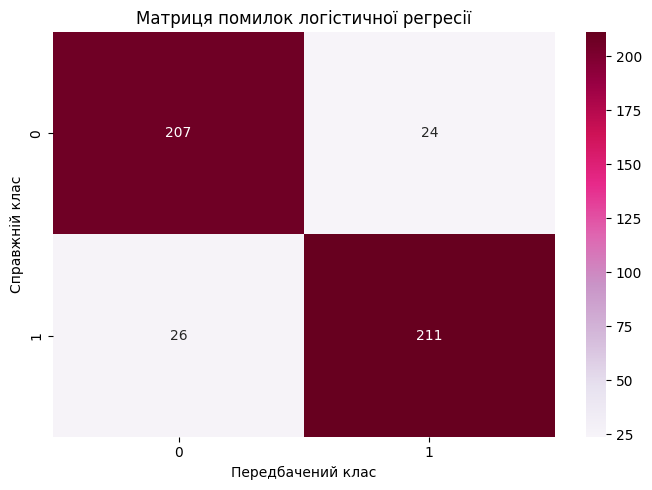

In [16]:
# TODO: обчисліть conf = confusion_matrix(y_test, y_pred)
# TODO: побудуйте теплову карту conf за допомогою sns.heatmap(...)

conf = confusion_matrix(y_test, y_pred)

print("Матриця помилок логістичної регресії:")
display(pd.DataFrame(
    conf,
    index =["Справжній 0", "Справжній 1"],
    columns = ["Передбачений 0", "Передбачений 1"]
))

plt.figure(figsize = (7, 5))

sns.heatmap(
    conf,
    annot = True,
    fmt = 'd',
    cmap = 'PuRd',
    xticklabels =['0', '1'],
    yticklabels = ['0', '1']
)

plt.title("Матриця помилок логістичної регресії")
plt.xlabel("Передбачений клас")
plt.ylabel("Справжній клас")
plt.tight_layout()
plt.show()

###**Пояснення:**

За допомогою функції `confusion_matrix()` обчислюємо матрицю помилок моделі логістичної регресії, порівнюючи справжні значення `y_test` із прогнозованими `y_pred`. Отриману матрицю виводимо у вигляді таблиці `DataFrame`, а за допомогою функції `sns.heatmap()` будуємо теплову карту для наочного відображення результатів класифікації.

У результаті встановлено, що модель **правильно визначила 207 спостережень класу 0 та 211 спостережень класу 1**. Водночас 24 спостереження класу 0 було помилково віднесено до класу 1, а 26 спостережень класу 1 – до класу 0.

Отже, із 468 тестових спостережень модель правильно класифікувала **418**, а помилково – **50**. Отримані результати відповідають раніше обчисленому значенню `Accuracy` = 89,32% та свідчать про приблизно однакову кількість помилок для обох класів.

In [17]:
# TODO: створіть DataFrame зі справжніми та передбаченими класами
# TODO: виведіть 10 випадкових рядків (sample(10, random_state=42))

results = pd.DataFrame({
    'Справжній клас': np.asarray(y_test),
    'Передбачений клас': y_pred
})

print("Порівняння справжніх і передбачених класів:")
print("10 випадкових зразків:")
display(results.sample(10, random_state = 42))

Порівняння справжніх і передбачених класів:
10 випадкових зразків:


,Справжній клас,Передбачений клас
55,0,1
63,0,0
33,1,0
297,1,1
72,1,1
228,0,0
209,1,1
9,1,1
428,0,0
231,1,1


###**Пояснення:**

У цій комірці створюємо DataFrame `results`, який містить справжні значення цільової змінної `y_test` та передбачені моделлю логістичної регресії значення `y_pred`.

За допомогою методу `sample()` випадковим чином вибираємо 10 спостережень із тестової вибірки. Параметр `random_state=42` забезпечує відтворюваність результатів.

Аналіз отриманої таблиці показав, що **для 8 із 10 випадкових спостережень модель правильно визначила клас**, а у 2 випадках допустила помилки. Зокрема, для спостереження з індексом 55 справжній клас 0 було помилково визначено як 1, а для спостереження з індексом 33 справжній клас 1 – як 0.

###**Висновок щодо якості логістичної регресії:**  
_Яких помилок більше? Чи достатньо однієї метрики Accuracy?_

За результатами аналізу матриці помилок встановлено, що модель логістичної регресії продемонструвала `Accuracy` = 89,32%, правильно класифікувавши 418 із 468 тестових спостережень.

Загалом модель допустила 50 помилок, із яких 24 є хибнопозитивними (`False` `Positive`), а 26 – хибнонегативними (`False Negative`). Отже, хибнонегативних помилок незначно більше, проте суттєвої різниці між кількістю помилок обох типів не спостерігається.

Аналіз 10 випадкових тестових спостережень також підтвердив здатність моделі правильно визначати більшість класів, оскільки 8 прогнозів виявилися правильними.

Водночас однієї метрики `Accuracy` недостатньо для повного оцінювання якості класифікації, оскільки вона не відображає розподіл помилок між класами. Тому необхідно також враховувати показники `Precision`, `Recall`, `F1-score` та матрицю помилок, які дозволяють детальніше оцінити ефективність моделі.

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [18]:
# TODO: створіть словники param_grid і param_dist
# Наприклад, дослідіть кілька значень C, solver та max_iter

param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear'],
    'max_iter': [100, 200, 300]
}

param_dist = {
    'C': np.logspace(-2, 2, 10),
    'solver': ['liblinear', 'lbfgs'],
    'max_iter': [100, 500]
}

print("Набір параметрів для GridSearchCV:\n")
print(param_grid)

print("\nНабір параметрів для RandomizedSearchCV:\n")
print(param_dist)

Набір параметрів для GridSearchCV:

{'C': [0.01, 0.1, 1, 10, 100], 'solver': ['lbfgs', 'liblinear'], 'max_iter': [100, 200, 300]}

Набір параметрів для RandomizedSearchCV:

{'C': array([1.00000000e-02, 2.78255940e-02, 7.74263683e-02, 2.15443469e-01,
       5.99484250e-01, 1.66810054e+00, 4.64158883e+00, 1.29154967e+01,
       3.59381366e+01, 1.00000000e+02]), 'solver': ['liblinear', 'lbfgs'], 'max_iter': [100, 500]}


###**Пояснення:**

У цій комірці створюємо словники `param_grid` і `param_dist`, які містять набори гіперпараметрів для пошуку оптимальної конфігурації моделі логістичної регресії.

Досліджуємо параметр `C`, який визначає силу регуляризації, `solver`, що задає алгоритм оптимізації, та `max_iter`, який встановлює максимальну кількість ітерацій навчання.

Для `GridSearchCV` задаємо 5 значень параметра `C`, 2 алгоритми оптимізації (`lbfgs`, `liblinear`) та 3 значення `max_iter`, що утворює 30 можливих комбінацій. Для `RandomizedSearchCV` використовуємо 10 логарифмічно розподілених значень `C`, 2 алгоритми оптимізації та 2 значення `max_iter`.

Отримані набори параметрів використовуватимемо для порівняння результатів повного та випадкового пошуку оптимальних налаштувань моделі.

In [19]:
# TODO: створіть GridSearchCV(LogisticRegression(), param_grid, cv=3, ...)
# TODO: виконайте fit(X_train_scaled, y_train)
# TODO: виведіть найкращі параметри

grid_search = GridSearchCV(
    LogisticRegression(random_state =42),
    param_grid = param_grid,
    cv = 3,
    scoring = 'accuracy',
    n_jobs = -1,
    verbose = 1
)

grid_search.fit(X_train_scaled, y_train)

print("\nНайкращі параметри GridSearchCV:")
print(grid_search.best_params_)

print(f"\nНайкраща Accuracy (CV): {grid_search.best_score_ * 100:.2f}%")

Fitting 3 folds for each of 30 candidates, totalling 90 fits

Найкращі параметри GridSearchCV:
{'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}

Найкраща Accuracy (CV): 86.74%


###**Пояснення:**

За допомогою `GridSearchCV` виконуємо повний перебір заданих комбінацій гіперпараметрів моделі логістичної регресії.

Параметр `cv=3` задає трикратну перехресну перевірку на навчальній вибірці, `scoring='accuracy'` визначає точність класифікації як критерій оцінювання, а `n_jobs=-1` дозволяє використовувати доступні процесорні ядра для паралельних обчислень.

У результаті перевірено **30 комбінацій параметрів**, що з урахуванням трикратної перехресної перевірки становить 90 навчань моделі.

Найкращими виявилися параметри **`C=10`, `solver='lbfgs'`, `max_iter=100`**. При цьому найвища середня точність класифікації за результатами перехресної перевірки становила **Accuracy (CV) = 86,74%**.

In [20]:
# TODO: створіть RandomizedSearchCV(LogisticRegression(), ...)
# TODO: виконайте fit(X_train_scaled, y_train)
# TODO: виведіть найкращі параметри

random_search = RandomizedSearchCV(
    LogisticRegression(random_state = 42),
    param_distributions = param_dist,
    n_iter = 20,
    cv = 3,
    scoring = 'accuracy',
    random_state = 42,
    n_jobs = -1,
    verbose = 1
)

random_search.fit(X_train_scaled, y_train)

print("\nНайкращі параметри RandomizedSearchCV:")
print(random_search.best_params_)

print(f"\nНайкраща Accuracy (CV): {random_search.best_score_ * 100:.2f}%")

Fitting 3 folds for each of 20 candidates, totalling 60 fits

Найкращі параметри RandomizedSearchCV:
{'solver': 'lbfgs', 'max_iter': 100, 'C': np.float64(100.0)}

Найкраща Accuracy (CV): 86.74%


###**Пояснення:**

За допомогою `RandomizedSearchCV` виконуємо випадковий пошук оптимальних гіперпараметрів моделі логістичної регресії.

Параметр `n_iter=20` задає кількість випадково вибраних комбінацій, `cv=3` забезпечує трикратну перехресну перевірку, а `scoring='accuracy'` використовується для оцінювання якості класифікації. Параметр `random_state=42` забезпечує відтворюваність результатів пошуку.

У результаті перевірено **20 комбінацій параметрів**, що відповідає 60 навчанням моделі.

Найкращими виявилися параметри **`C=100`, `solver='lbfgs'`, `max_iter=100`**. Отримана середня точність класифікації становила **Accuracy (CV) = 86,74%**, що збігається з результатом `GridSearchCV`.

In [21]:
# TODO: отримайте найкращу модель з grid або random_search
# TODO: побудуйте прогноз на X_test_scaled
# TODO: виведіть Accuracy та classification_report

if grid_search.best_score_ >= random_search.best_score_:
    best_model = grid_search.best_estimator_
    best_method = "GridSearchCV"
else:
    best_model = random_search.best_estimator_
    best_method = "RandomizedSearchCV"

print("Обраний метод:", best_method)
print("Найкращі параметри:", best_model.get_params())

y_pred_best = best_model.predict(X_test_scaled)

accuracy_best = accuracy_score(y_test, y_pred_best)

print(f"\nAccuracy найкращої моделі: {accuracy_best * 100:.2f}%")

print("\nЗвіт про класифікацію:")
print(classification_report(y_test, y_pred_best))

Обраний метод: GridSearchCV
Найкращі параметри: {'C': 10, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 100, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}

Accuracy найкращої моделі: 89.32%

Звіт про класифікацію:
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



###**Пояснення:**

У цій комірці порівнюємо результати підбору гіперпараметрів методами `GridSearchCV` та `RandomizedSearchCV` за показником середньої точності перехресної перевірки `best_score_`.

Оскільки обидва методи забезпечили однакову `Accuracy (CV)` = 86,74%, для подальшого оцінювання обрано модель, отриману за допомогою **`GridSearchCV`**, із параметрами `C=10`, `solver='lbfgs'` та `max_iter=100`.

За допомогою методу `predict()` отримуємо прогнози для стандартизованої тестової вибірки `X_test_scaled`, після чого оцінюємо якість класифікації за допомогою `accuracy_score()` та `classification_report()`.

У результаті отримано **Accuracy = 89,32%**, що відповідає точності базової моделі логістичної регресії до підбору гіперпараметрів.

Для обох класів показники `Precision`, `Recall` та `F1-score` залишилися приблизно на рівні 0,89–0,90.

Отже, підбір гіперпараметрів дозволив визначити оптимальну конфігурацію серед перевірених варіантів, проте не забезпечив підвищення якості класифікації на тестовій вибірці.

###**Висновок про підбір параметрів:**  
_Який метод пошуку обрав які параметри? Чи покращилась якість порівняно з базовою моделлю?_

За результатами підбору гіперпараметрів моделі логістичної регресії встановлено, що обидва методи, `GridSearchCV` та `RandomizedSearchCV`, забезпечили однакову середню точність класифікації `Accuracy (CV) = 86,74%`.

Метод `GridSearchCV` визначив найкращу конфігурацію з параметрами `C=10`, `solver='lbfgs'` та `max_iter=100`, перевіривши 30 комбінацій. Метод `RandomizedSearchCV` знайшов параметри `C=100`, `solver='lbfgs'` та `max_iter=100`, перевіривши лише 20 комбінацій. Таким чином, випадковий пошук дозволив отримати аналогічний результат за меншої кількості навчань моделі.

Для остаточного оцінювання обрано модель `GridSearchCV`, яка продемонструвала `Accuracy = 89,32%` на тестовій вибірці. Порівняння з базовою моделлю логістичної регресії показало, що після підбору гіперпараметрів точність класифікації не змінилася. Показники `Precision`, `Recall` та `F1-score` також залишилися на попередньому рівні.

Отже, підбір гіперпараметрів не забезпечив покращення якості логістичної регресії на тестовій вибірці, проте дозволив дослідити вплив налаштувань моделі та порівняти ефективність двох методів пошуку.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [22]:
# TODO: побудуйте SVC() і DecisionTreeClassifier(random_state=42)
# TODO: навчіть три моделі та отримайте їх передбачення
# TODO: створіть таблицю з Accuracy та F1-score для кожної моделі
# TODO: визначте найкращу модель

models = {
    'Logistic Regression': best_model,
    'SVM': SVC(),
    'Decision Tree': DecisionTreeClassifier(random_state = 42)
}

results = []

for name, model in models.items():

    if name == 'Decision Tree':
        X_tr = X_train
        X_te = X_test
    else:
        X_tr = X_train_scaled
        X_te = X_test_scaled

    model.fit(X_tr, y_train)

    y_pred_model = model.predict(X_te)

    accuracy = accuracy_score(y_test, y_pred_model)
    f1 = f1_score(y_test, y_pred_model, average = 'macro')

    results.append({
        'Модель': name,
        'Accuracy (%)': accuracy * 100,
        'F1-score': f1
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by=['Accuracy (%)', 'F1-score'],
    ascending = False
).reset_index(drop = True)

print("Порівняння моделей класифікації:")
display(results_df.round(4))

best_model_name = results_df.iloc[0]['Модель']

print("\nНайкраща модель:", best_model_name)

Порівняння моделей класифікації:


,Модель,Accuracy (%),F1-score
0,SVM,95.9402,0.9594
1,Logistic Regression,89.3162,0.8932
2,Decision Tree,86.3248,0.8632



Найкраща модель: SVM


###**Пояснення:**

У цій комірці створюємо та порівнюємо три моделі бінарної класифікації: логістичну регресію (`LogisticRegression`), метод опорних векторів (`SVC`) та дерево рішень (`DecisionTreeClassifier`).

Для логістичної регресії використовуємо модель із попередньо підібраними гіперпараметрами. Модель `SVM` навчаємо на стандартизованих даних, а дерево рішень – на початкових числових ознаках, оскільки цей алгоритм не потребує стандартизації.

За допомогою циклу `for` послідовно навчаємо всі три моделі методом `fit()` та отримуємо прогнози для однакової тестової вибірки методом `predict()`. Для оцінювання якості класифікації використовуємо метрики `accuracy_score()` та `f1_score()` із параметром `average='macro'`.

Отримані результати зберігаємо у DataFrame та сортуємо за спаданням `Accuracy` і `F1-score` для визначення найкращої моделі.

За результатами порівняння **найвищу якість класифікації продемонструвала модель SVM**, для якої `Accuracy` становила **95,94%**, а `F1-score` – **0,9594**. Логістична регресія забезпечила `Accuracy` = 89,32% та `F1-score` = 0,8932, тоді як дерево рішень показало найнижчі результати: `Accuracy` = 86,32% та `F1-score` = 0,8632.

Отже, **найкращою серед досліджених моделей виявилася SVM**, яка перевершила логістичну регресію за `Accuracy` приблизно на 6,62 відсотка , а дерево рішень – на 9,62 відсотка. Високі значення `Accuracy` та `F1-score` свідчать про ефективність методу опорних векторів для класифікації даних `Cure the Princess`.

###*****Додатковий експеримент: дослідження впливу видалення викидів на якість моделей класифікації**

**Видалення потенційних викидів із навчальної вибірки**

In [23]:
# Визначення рядків без потенційних викидів
mask_clean = ~outliers.any(axis = 1)

# Формування навчальних даних без викидів
X_train_clean = X_train.loc[mask_clean].copy()
y_train_clean = y_train.loc[mask_clean].copy()

print("Початкова кількість навчальних спостережень:", len(X_train))
print("Кількість спостережень після видалення викидів:", len(X_train_clean))
print("Кількість видалених спостережень:", len(X_train) - len(X_train_clean))

Початкова кількість навчальних спостережень: 1870
Кількість спостережень після видалення викидів: 1771
Кількість видалених спостережень: 99


###**Пояснення:**

Виконуємо видалення потенційних викидів із навчальної вибірки, використовуючи результати попереднього дослідження за правилом `1,5 IQR`.

За допомогою методу `any(axis=1)` визначаємо рядки, які містять хоча б один потенційний викид, а оператор ~ дозволяє сформувати логічну маску для відбору спостережень без викидів.

Далі за допомогою `loc[]` та `copy()` створюємо очищені навчальні вибірки `X_train_clean` і `y_train_clean`, зберігаючи відповідність між ознаками та цільовою змінною.

У результаті із 1870 навчальних спостережень видалено 99 записів, після чого залишилося 1771 спостереження. Таким чином, кількість навчальних даних зменшилася приблизно на 5,29%.

Видалення виконано виключно на навчальній вибірці, тоді як тестові дані залишилися незмінними для забезпечення коректного порівняння моделей.

**Стандартизація очищених навчальних даних**

In [24]:
# Стандартизація навчальних даних без викидів
scaler_clean = StandardScaler()

X_train_clean_scaled = scaler_clean.fit_transform(X_train_clean)
X_test_clean_scaled = scaler_clean.transform(X_test)

###**Пояснення:**

Повторно виконуємо стандартизацію числових ознак після видалення потенційних викидів із навчальної вибірки.

Для цього створюємо новий об'єкт `StandardScaler`, який дозволяє обчислити параметри стандартизації на очищених даних.

За допомогою методу `fit_transform()` стандартизуємо навчальну вибірку `X_train_clean`, а методом `transform()` застосовуємо отримані параметри до початкової тестової вибірки `X_test`.

Таким чином, параметри стандартизації визначаються лише за очищеними навчальними даними, що дозволяє уникнути витоку інформації з тестової вибірки та забезпечити коректне повторне навчання моделей.

**Повторне навчання моделей логістичної регресії, SVM та дерева рішень**

In [25]:
# Моделі для експерименту
models_clean = {
    'Logistic Regression': LogisticRegression(
        **grid_search.best_params_, random_state = 42
    ),
    'SVM': SVC(),
    'Decision Tree': DecisionTreeClassifier(random_state = 42)
}

results_clean = []

for name, model_clean in models_clean.items():

    if name == 'Decision Tree':
        X_tr = X_train_clean
        X_te = X_test
    else:
        X_tr = X_train_clean_scaled
        X_te = X_test_clean_scaled

    model_clean.fit(X_tr, y_train_clean)

    y_pred_clean = model_clean.predict(X_te)

    accuracy_clean = accuracy_score(y_test, y_pred_clean)
    f1_clean = f1_score(y_test, y_pred_clean, average='macro')

    results_clean.append({
        'Модель': name,
        'Accuracy (%)': accuracy_clean * 100,
        'F1-score': f1_clean
    })

results_clean_df = pd.DataFrame(results_clean)

print("Результати моделей після видалення викидів:")
display(results_clean_df.round(4))

Результати моделей після видалення викидів:


,Модель,Accuracy (%),F1-score
0,Logistic Regression,89.1026,0.8910
1,SVM,95.9402,0.9594
2,Decision Tree,84.4017,0.8440


###**Пояснення:**

Повторно створюємо та навчаємо три моделі бінарної класифікації: логістичну регресію (`LogisticRegression`), метод опорних векторів (`SVC`) та дерево рішень (`DecisionTreeClassifier`).

Для логістичної регресії використовуємо раніше підібрані гіперпараметри, а для `SVM` і дерева рішень залишаємо попередні налаштування. Моделі логістичної регресії та `SVM` навчаємо на стандартизованій очищеній вибірці, а дерево рішень – на початкових значеннях ознак після видалення викидів.

За допомогою методу `fit()` виконуємо навчання моделей, а методом `predict()` отримуємо прогнози для незмінної тестової вибірки. Якість класифікації оцінюємо за метриками `Accuracy` та `F1-score`.

У результаті найвищу точність знову продемонструвала модель `SVM – 95,94%`, із `F1-score = 0,9594`. Логістична регресія забезпечила `Accuracy = 89,10%` та `F1-score = 0,8910`, тоді як дерево рішень отримало `Accuracy = 84,40%` та `F1-score = 0,8440`.

Отримані результати свідчать, що навіть після видалення потенційних викидів `SVM` залишається найефективнішою серед досліджених моделей.

**Порівняння якості класифікації до та після видалення викидів.**

In [26]:
# Порівняння результатів моделей
comparison = results_df.merge(
    results_clean_df,
    on ='Модель',
    suffixes = ('_до', '_після')
)

comparison['Зміна Accuracy (в.п.)'] = (
    comparison['Accuracy (%)_після'] -
    comparison['Accuracy (%)_до']
)

comparison['Зміна F1-score'] = (
    comparison['F1-score_після'] -
    comparison['F1-score_до']
)

print("Порівняння моделей до та після видалення викидів:")
display(comparison.round(4))

Порівняння моделей до та після видалення викидів:


,Модель,Accuracy (%)_до,F1-score_до,Accuracy (%)_після,F1-score_після,Зміна Accuracy (в.п.),Зміна F1-score
0,SVM,95.9402,0.9594,95.9402,0.9594,0.0000,0.0000
1,Logistic Regression,89.3162,0.8932,89.1026,0.8910,-0.2137,-0.0021
2,Decision Tree,86.3248,0.8632,84.4017,0.8440,-1.9231,-0.0193


###**Пояснення:**

Порівнюємо якість трьох моделей класифікації до та після видалення потенційних викидів із навчальної вибірки.

За допомогою методу `merge()` об'єднуємо таблиці результатів `results_df` і `results_clean_df` за назвами моделей. Далі обчислюємо різницю між показниками `Accuracy` та `F1-score` до і після очищення даних.

Аналіз отриманої таблиці показав, що для моделі `SVM` результати залишилися незмінними: `Accuracy = 95,94%` , `F1-score = 0,9594`.

Для логістичної регресії `Accuracy` знизилася з 89,32% до 89,10%, тобто на 0,21 відсотка, а `F1-score` зменшилася з 0,8932 до 0,8910.

Найбільше погіршення спостерігається для дерева рішень: `Accuracy` знизилася з 86,32% до 84,40%, тобто на 1,92 відсотка, а `F1-score` – з 0,8632 до 0,8440.

Таким чином, видалення потенційних викидів не забезпечило покращення якості жодної з досліджених моделей. Навпаки, для логістичної регресії та дерева рішень спостерігається зниження точності класифікації.

### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?
2. Що показали дослідження викидів і кореляцій **на навчальній вибірці**?
3. Якої якості досягла базова логістична регресія?
4. Чи покращив підбір гіперпараметрів метрики моделі?
5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

**Ваші висновки:**  
_Впишіть відповідь тут._

---
За результатами первинного аналізу датасету `Cure the Princess` встановлено, що він містить **2338 спостережень і 14 стовпців**, із яких 13 є числовими ознаками, а один – цільовою змінною `Cured`. Пропущених значень і дублікатів не виявлено, що свідчить про належну початкову якість даних. Навчальна вибірка містить 1870 спостережень, а тестова – 468. Розподіл класів у навчальній вибірці виявився майже рівномірним: 50,59% для класу 0 та 49,41% для класу 1, тому застосування додаткових методів балансування не було необхідним.

Дослідження викидів за правилом `1,5 IQR` показало, що найбільшу кількість потенційних викидів містять ознаки `Witch's Brew` (33), `Unicorn Horn` (20), `Minotaur Horn` (18) та `Chimera Fang` (13). Кореляційний аналіз навчальної вибірки виявив переважно слабкі лінійні зв'язки між числовими ознаками. Найвищу кореляцію за модулем встановлено між `Mermaid Tears` і `Kraken Ink` (0,49), а найсильніший зв'язок із цільовою змінною `Cured` мають ознаки `Troll Hair` (0,4888) та `Witch's Brew` (0,2470). Суттєвих ознак мультиколінеарності не виявлено. Додатковий експеримент із видаленням 99 потенційно аномальних спостережень показав, що очищення навчальної вибірки не покращило якість жодної з досліджених моделей.

Базова модель логістичної регресії продемонструвала **Accuracy = 89,32%** на тестовій вибірці. Із 468 спостережень модель правильно класифікувала 418, допустивши 50 помилок, серед яких 24 хибнопозитивні та 26 хибнонегативних. Показники `Precision`, `Recall` та `F1-score` для обох класів становили приблизно 0,89–0,90, що свідчить про достатньо високу та збалансовану якість класифікації. Водночас `Accuracy` необхідно розглядати разом з іншими метриками, оскільки вона не відображає характер помилок моделі.

Підбір гіперпараметрів за допомогою `GridSearchCV` та `RandomizedSearchCV` не забезпечив підвищення точності логістичної регресії. Обидва методи отримали однакову середню `Accuracy = 86,74%` за результатами трикратної перехресної перевірки. Найкращою конфігурацією, обраною за допомогою `GridSearchCV`, стали параметри `C=10`, `solver='lbfgs'` та `max_iter=100`. Після їх застосування точність на тестовій вибірці залишилася незмінною – 89,32%. Отже, базова модель уже забезпечувала достатньо ефективну класифікацію, а додаткове налаштування не дало помітного покращення.

Порівняння логістичної регресії, методу опорних векторів (`SVM`) та дерева рішень показало, що **найкращою моделлю виявилася SVM**, яка забезпечила `Accuracy = 95,94%` та `F1-score = 0,9594`. Логістична регресія отримала `Accuracy = 89,32%` та `F1-score = 0,8932`, а дерево рішень – `Accuracy = 86,32%` та `F1-score = 0,8632`. Перевага `SVM` може пояснюватися здатністю алгоритму враховувати складні нелінійні залежності між ознаками. Крім того, під час додаткового експерименту після видалення викидів її показники залишилися незмінними, що свідчить про стійкість результатів цієї моделі до виконаного очищення навчальних даних.

**Отже, для задачі бінарної класифікації датасету *Cure the Princess* найдоцільніше використовувати модель SVM**, оскільки вона продемонструвала найвищі значення `Accuracy` та `F1-score` серед трьох досліджених алгоритмів. Водночас результати додаткового експерименту показали, що автоматичне видалення потенційних викидів не є необхідним, оскільки воно не забезпечило підвищення якості класифікації.

---
**Перед здачею:** перевірте, що всі потрібні клітинки виконуються послідовно, а результати й висновки присутні у файлі `.ipynb`.